<a href="https://colab.research.google.com/github/shivanikasha16/supply_chain_analysis/blob/main/supplyChainAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving monthly_mode_time_2015_2025.csv to monthly_mode_time_2015_2025.csv


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("monthly_mode_time_2015_2025.csv")

df.head()

,MMSI,Port,YearMonth,anchor_hours,berth_hours,manoeuvre_hours,transit_hours,unknown_hoteling_hours,total_mode_hours
0,205609000,Houston,2015-01,0.0,0.000000,0.000000,9.024444,0.0,9.024444
1,209250000,Houston,2015-01,0.0,0.000000,0.000000,3.480000,0.0,3.480000
2,209495000,Houston,2015-01,0.0,0.000000,0.000000,3.290000,0.0,3.290000
3,209641000,Houston,2015-01,0.0,8.912222,0.405556,1.247778,0.0,10.565556
4,210959000,Houston,2015-01,0.0,90.007778,1.074444,11.127222,0.0,102.209444


In [ ]:
monthly_port = (
    df.groupby(["Port", "YearMonth"])
      .agg(
          avg_anchor_hours=("anchor_hours", "mean"),
          total_anchor_hours=("anchor_hours", "sum"),
          vessel_count=("MMSI", "nunique")
      )
      .reset_index()
)

monthly_port.head(10)

,Port,YearMonth,avg_anchor_hours,total_anchor_hours,vessel_count
0,Houston,2015-01,0.0,0.0,358
1,Houston,2015-02,0.0,0.0,337
2,Houston,2015-03,0.0,0.0,354
3,Houston,2015-04,0.0,0.0,392
4,Houston,2015-05,0.0,0.0,342
5,Houston,2015-06,0.0,0.0,345
6,Houston,2015-07,0.0,0.0,334
7,Houston,2015-08,0.0,0.0,358
8,Houston,2015-09,0.0,0.0,342
9,Houston,2015-10,0.0,0.0,279


In [ ]:
monthly_port = (
    df.groupby(["Port", "YearMonth"])
      .agg(
          avg_anchor_hours=("anchor_hours", "mean"),
          avg_berth_hours=("berth_hours", "mean"),
          avg_manoeuvre_hours=("manoeuvre_hours", "mean"),
          avg_transit_hours=("transit_hours", "mean"),
          avg_total_mode_hours=("total_mode_hours", "mean"),
          vessel_count=("MMSI", "nunique")
      )
      .reset_index()
)

monthly_port.head(10)

,Port,YearMonth,avg_anchor_hours,avg_berth_hours,avg_manoeuvre_hours,avg_transit_hours,avg_total_mode_hours,vessel_count
0,Houston,2015-01,0.0,8.665688,0.137721,3.926182,12.762603,358
1,Houston,2015-02,0.0,7.530808,0.132198,4.292418,11.958491,337
2,Houston,2015-03,0.0,9.362067,0.155581,3.481157,14.132167,354
3,Houston,2015-04,0.0,6.357202,0.108807,4.050955,10.531192,392
4,Houston,2015-05,0.0,7.688365,0.133028,4.439997,12.264084,342
5,Houston,2015-06,0.0,6.266101,0.138859,4.228163,10.634287,345
6,Houston,2015-07,0.0,7.345538,0.124785,4.043589,11.514837,334
7,Houston,2015-08,0.0,6.225192,0.130366,4.196431,10.612225,358
8,Houston,2015-09,0.0,5.094656,0.083102,3.995151,9.174482,342
9,Houston,2015-10,0.0,7.068667,0.084963,3.262435,10.417156,279


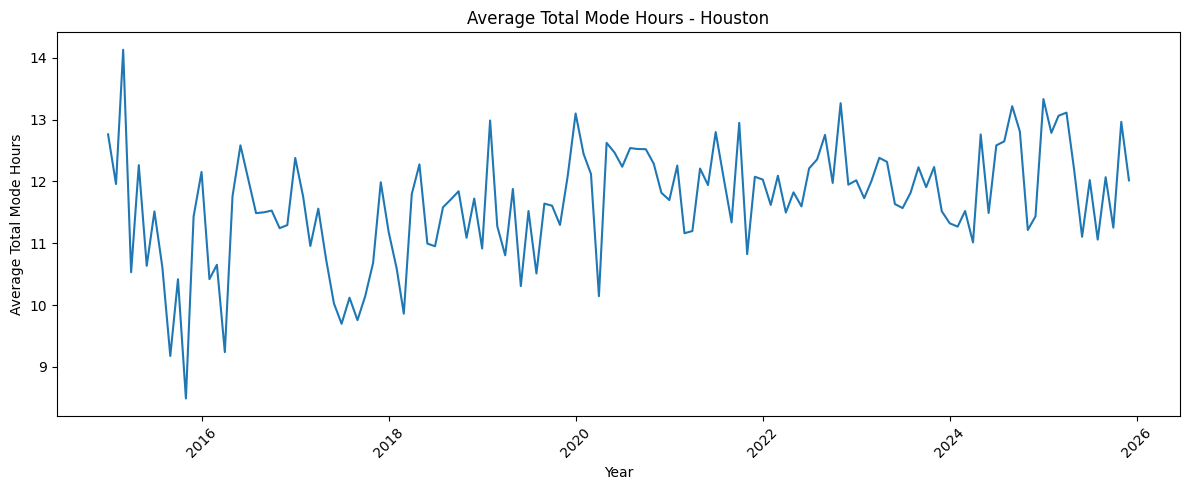

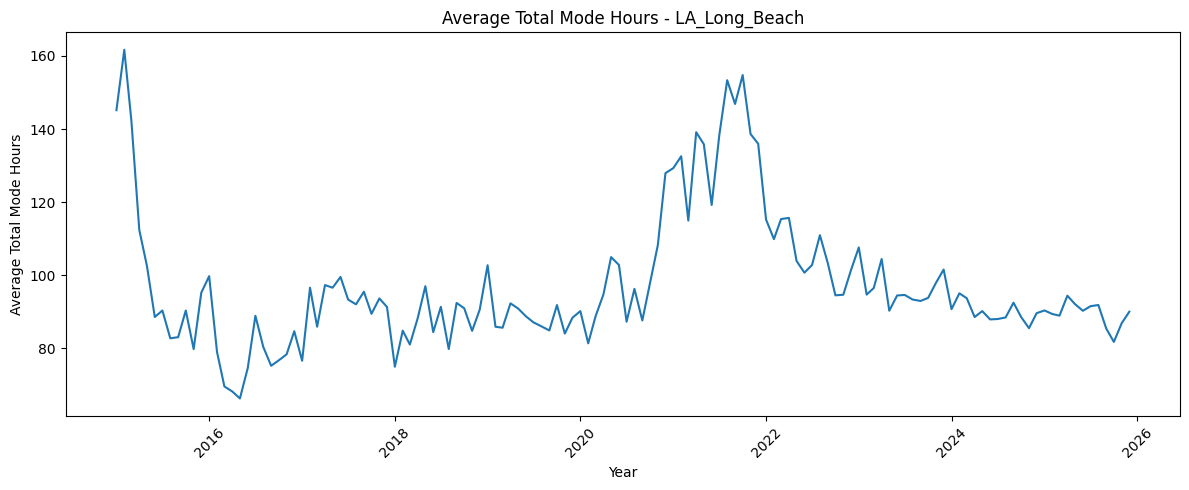

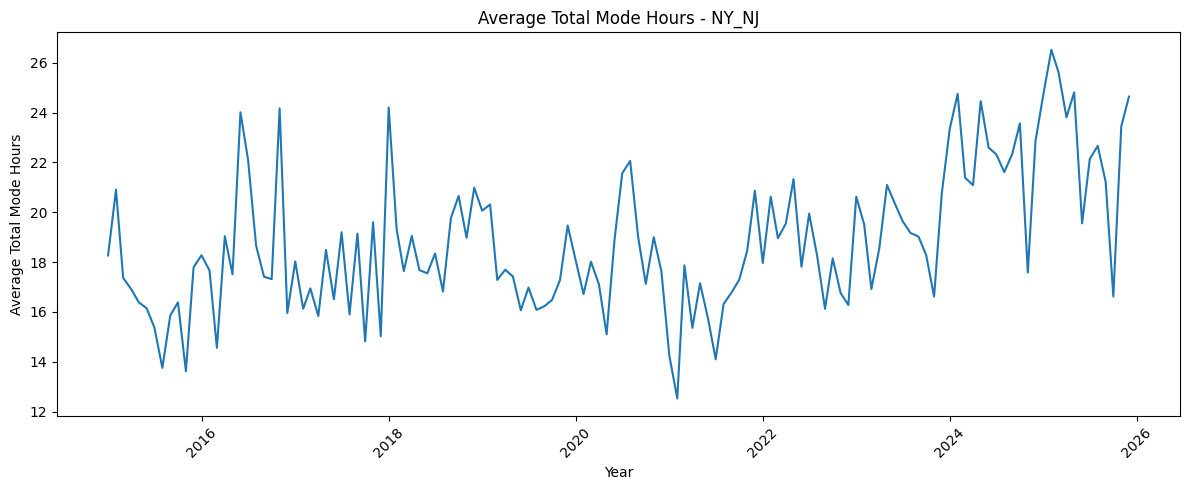

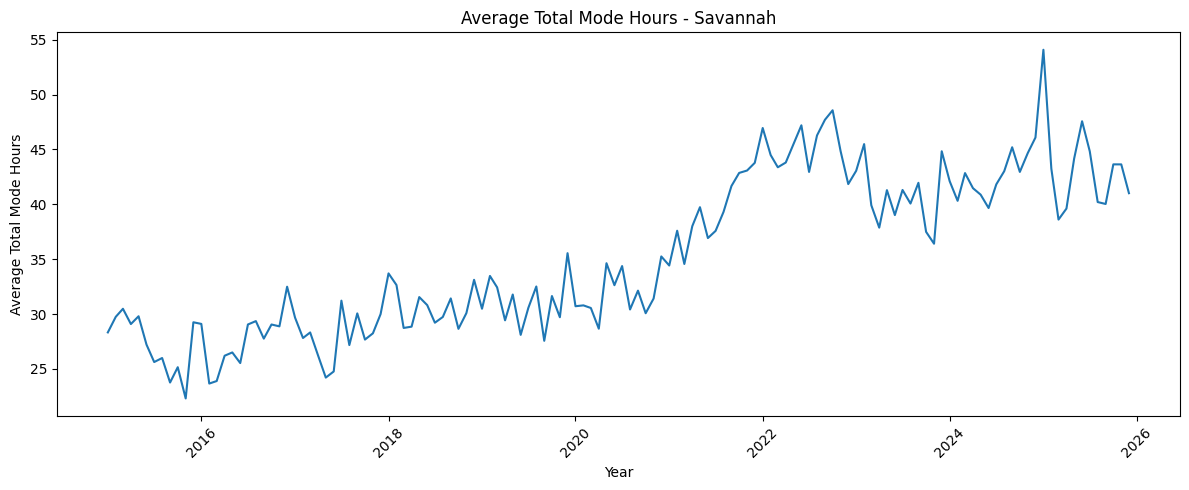

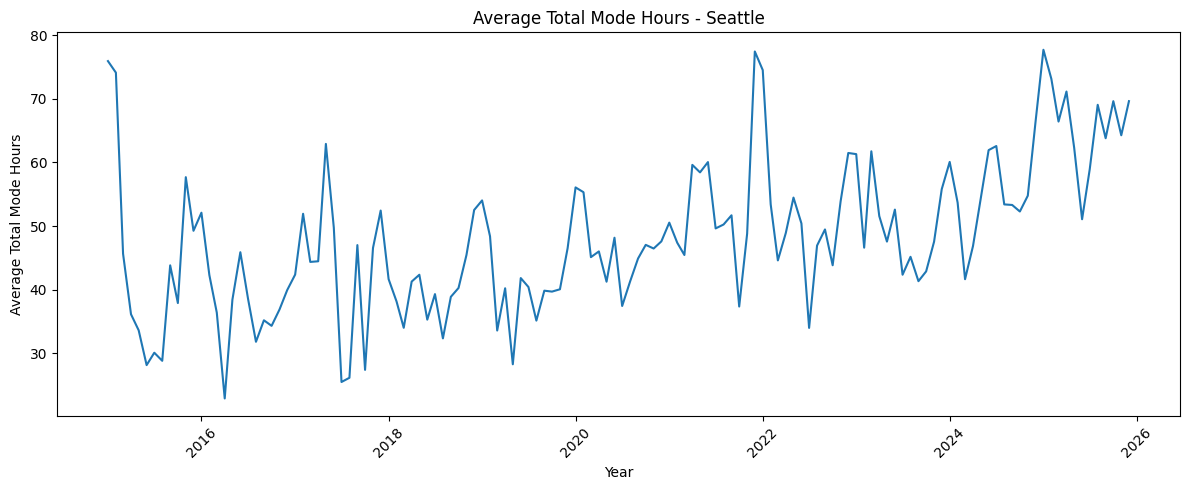

In [ ]:
import matplotlib.pyplot as plt

monthly_port["YearMonth"] = pd.to_datetime(monthly_port["YearMonth"])

for port in monthly_port["Port"].unique():
    temp = monthly_port[monthly_port["Port"] == port]

    plt.figure(figsize=(12, 5))
    plt.plot(temp["YearMonth"], temp["avg_total_mode_hours"])
    plt.title(f"Average Total Mode Hours - {port}")
    plt.xlabel("Year")
    plt.ylabel("Average Total Mode Hours")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving monthly_dwell_2015_2025.csv to monthly_dwell_2015_2025 (1).csv


In [ ]:
dwell = pd.read_csv("monthly_dwell_2015_2025.csv")
dwell.head()

,Port,YearMonth,UniqueVessels,MeanDwellDays,MedianDwellDays,StdDwellDays,MinDwellDays,MaxDwellDays,TotalObservations,AvgVesselLength,PortName,days_ok,days_total
0,Houston,2015-01,358,4.792480,2.299248,6.303059,0.026921,30.306910,100099,185.907011,Houston,31,31
1,LA_Long_Beach,2015-01,205,7.438796,5.518542,6.889828,0.000810,30.999595,658649,249.969317,LA_Long_Beach,31,31
2,NY_NJ,2015-01,235,3.257377,1.140579,5.866861,0.016655,30.039572,98747,236.475830,NY_NJ,31,31
3,Savannah,2015-01,147,1.870332,0.981782,3.655530,0.082072,28.108530,109236,255.806259,Savannah,31,31
4,Seattle,2015-01,108,6.202327,4.156013,7.110874,0.006100,30.999109,215003,238.868611,Seattle,31,31


In [ ]:
dwell.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Port               660 non-null    object 
 1   YearMonth          660 non-null    object 
 2   UniqueVessels      660 non-null    int64  
 3   MeanDwellDays      660 non-null    float64
 4   MedianDwellDays    660 non-null    float64
 5   StdDwellDays       660 non-null    float64
 6   MinDwellDays       660 non-null    float64
 7   MaxDwellDays       660 non-null    float64
 8   TotalObservations  660 non-null    int64  
 9   AvgVesselLength    660 non-null    float64
 10  PortName           660 non-null    object 
 11  days_ok            660 non-null    int64  
 12  days_total         660 non-null    int64  
dtypes: float64(6), int64(4), object(3)
memory usage: 67.2+ KB


In [ ]:
dwell["YearMonth"] = pd.to_datetime(dwell["YearMonth"])

dwell.head()

,Port,YearMonth,UniqueVessels,MeanDwellDays,MedianDwellDays,StdDwellDays,MinDwellDays,MaxDwellDays,TotalObservations,AvgVesselLength,PortName,days_ok,days_total
0,Houston,2015-01-01,358,4.792480,2.299248,6.303059,0.026921,30.306910,100099,185.907011,Houston,31,31
1,LA_Long_Beach,2015-01-01,205,7.438796,5.518542,6.889828,0.000810,30.999595,658649,249.969317,LA_Long_Beach,31,31
2,NY_NJ,2015-01-01,235,3.257377,1.140579,5.866861,0.016655,30.039572,98747,236.475830,NY_NJ,31,31
3,Savannah,2015-01-01,147,1.870332,0.981782,3.655530,0.082072,28.108530,109236,255.806259,Savannah,31,31
4,Seattle,2015-01-01,108,6.202327,4.156013,7.110874,0.006100,30.999109,215003,238.868611,Seattle,31,31


In [ ]:
dwell[["Port", "YearMonth", "MeanDwellDays"]].head(10)

,Port,YearMonth,MeanDwellDays
0,Houston,2015-01-01,4.792480
1,LA_Long_Beach,2015-01-01,7.438796
2,NY_NJ,2015-01-01,3.257377
3,Savannah,2015-01-01,1.870332
4,Seattle,2015-01-01,6.202327
5,Houston,2015-02-01,4.932298
6,LA_Long_Beach,2015-02-01,7.676772
7,NY_NJ,2015-02-01,3.352608
8,Savannah,2015-02-01,1.561266
9,Seattle,2015-02-01,5.554373


In [ ]:
dwell.groupby("Port")["MeanDwellDays"].agg(["min", "max", "mean", "std"])

,min,max,mean,std
Port,,,,
Houston,2.807201,5.645575,4.469722,0.409328
LA_Long_Beach,3.269062,7.730778,5.305080,0.832583
NY_NJ,2.195640,4.218263,3.462252,0.346776
Savannah,1.185001,3.133521,2.047688,0.424129
Seattle,2.288747,6.940802,4.605873,0.862711


In [ ]:
dwell["congestion_threshold"] = (
    dwell.groupby("Port")["MeanDwellDays"]
         .transform(lambda x: x.quantile(0.75))
)

dwell["Congested"] = (
    dwell["MeanDwellDays"] > dwell["congestion_threshold"]
).astype(int)

dwell[["Port", "YearMonth", "MeanDwellDays",
       "congestion_threshold", "Congested"]].head(10)

,Port,YearMonth,MeanDwellDays,congestion_threshold,Congested
0,Houston,2015-01-01,4.792480,4.690145,1
1,LA_Long_Beach,2015-01-01,7.438796,5.551379,1
2,NY_NJ,2015-01-01,3.257377,3.656513,0
3,Savannah,2015-01-01,1.870332,2.334815,0
4,Seattle,2015-01-01,6.202327,5.221395,1
5,Houston,2015-02-01,4.932298,4.690145,1
6,LA_Long_Beach,2015-02-01,7.676772,5.551379,1
7,NY_NJ,2015-02-01,3.352608,3.656513,0
8,Savannah,2015-02-01,1.561266,2.334815,0
9,Seattle,2015-02-01,5.554373,5.221395,1


In [ ]:
dwell["Congested"].value_counts()

,count
Congested,
0,495
1,165


In [ ]:
dwell["Target_Next_Month"] = (
    dwell.groupby("Port")["Congested"].shift(-1)
)

dwell[["Port", "YearMonth", "Congested", "Target_Next_Month"]].head(10)

,Port,YearMonth,Congested,Target_Next_Month
0,Houston,2015-01-01,1,1.0
1,LA_Long_Beach,2015-01-01,1,1.0
2,NY_NJ,2015-01-01,0,0.0
3,Savannah,2015-01-01,0,0.0
4,Seattle,2015-01-01,1,1.0
5,Houston,2015-02-01,1,1.0
6,LA_Long_Beach,2015-02-01,1,1.0
7,NY_NJ,2015-02-01,0,0.0
8,Savannah,2015-02-01,0,0.0
9,Seattle,2015-02-01,1,0.0


In [ ]:
dwell = dwell.dropna(subset=["Target_Next_Month"])

dwell["Target_Next_Month"] = dwell["Target_Next_Month"].astype(int)

dwell.shape

(655, 16)

In [ ]:
monthly_features = (
    df.groupby(["Port", "YearMonth"])
      .agg(
          avg_anchor_hours=("anchor_hours", "mean"),
          avg_berth_hours=("berth_hours", "mean"),
          avg_manoeuvre_hours=("manoeuvre_hours", "mean"),
          avg_transit_hours=("transit_hours", "mean"),
          avg_total_mode_hours=("total_mode_hours", "mean"),
          vessel_count=("MMSI", "nunique")
      )
      .reset_index()
)

monthly_features.head()

,Port,YearMonth,avg_anchor_hours,avg_berth_hours,avg_manoeuvre_hours,avg_transit_hours,avg_total_mode_hours,vessel_count
0,Houston,2015-01,0.0,8.665688,0.137721,3.926182,12.762603,358
1,Houston,2015-02,0.0,7.530808,0.132198,4.292418,11.958491,337
2,Houston,2015-03,0.0,9.362067,0.155581,3.481157,14.132167,354
3,Houston,2015-04,0.0,6.357202,0.108807,4.050955,10.531192,392
4,Houston,2015-05,0.0,7.688365,0.133028,4.439997,12.264084,342


In [ ]:
monthly_features["YearMonth"] = pd.to_datetime(monthly_features["YearMonth"])
model_data = pd.merge(
    monthly_features,
    dwell[["Port", "YearMonth", "Target_Next_Month"]],
    on=["Port", "YearMonth"],
    how="inner"
)

model_data.shape

(655, 9)

In [ ]:
model_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 655 entries, 0 to 654
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Port                  655 non-null    object        
 1   YearMonth             655 non-null    datetime64[ns]
 2   avg_anchor_hours      655 non-null    float64       
 3   avg_berth_hours       655 non-null    float64       
 4   avg_manoeuvre_hours   655 non-null    float64       
 5   avg_transit_hours     655 non-null    float64       
 6   avg_total_mode_hours  655 non-null    float64       
 7   vessel_count          655 non-null    int64         
 8   Target_Next_Month     655 non-null    int64         
dtypes: datetime64[ns](1), float64(5), int64(2), object(1)
memory usage: 46.2+ KB


In [ ]:
X = model_data.drop(columns=["Target_Next_Month", "Port", "YearMonth"])
y = model_data["Target_Next_Month"]

X.shape, y.shape

((655, 6), (655,))

In [ ]:
split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((524, 6), (131, 6), (524,), (131,))

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=300,
                       random_state=42)

In [ ]:
y_pred = model.predict(X_test)

y_pred[:20]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7557251908396947

Classification Report:
              precision    recall  f1-score   support

           0       0.76      1.00      0.86        99
           1       0.00      0.00      0.00        32

    accuracy                           0.76       131
   macro avg       0.38      0.50      0.43       131
weighted avg       0.57      0.76      0.65       131


Confusion Matrix:
[[99  0]
 [32  0]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
y_prob = model.predict_proba(X_test)[:, 1]

y_prob[:20]

array([0.11      , 0.11666667, 0.17      , 0.19      , 0.18666667,
       0.19666667, 0.19333333, 0.20666667, 0.16      , 0.16666667,
       0.16666667, 0.18666667, 0.16666667, 0.15666667, 0.18666667,
       0.16333333, 0.19      , 0.16333333, 0.14333333, 0.18666667])

In [ ]:
pd.DataFrame({
    "Actual": y_test,
    "Probability": y_prob
}).groupby("Actual")["Probability"].agg(["min", "mean", "max"])

,min,mean,max
Actual,,,
0,0.066667,0.156801,0.233333
1,0.086667,0.137604,0.220000


In [ ]:
model_data["Previous_Month_Congested"] = (
    model_data.groupby("Port")["Target_Next_Month"]
    .shift(1)
)

model_data[[
    "Port",
    "YearMonth",
    "Target_Next_Month",
    "Previous_Month_Congested"
]].head(10)


,Port,YearMonth,Target_Next_Month,Previous_Month_Congested
0,Houston,2015-01-01,1,NaN
1,Houston,2015-02-01,1,1.0
2,Houston,2015-03-01,0,1.0
3,Houston,2015-04-01,1,0.0
4,Houston,2015-05-01,1,1.0
5,Houston,2015-06-01,0,1.0
6,Houston,2015-07-01,0,0.0
7,Houston,2015-08-01,0,0.0
8,Houston,2015-09-01,0,0.0
9,Houston,2015-10-01,0,0.0


In [ ]:
model_data["Previous_Month_Congested"] = (
    model_data["Previous_Month_Congested"].fillna(0)
)

model_data["Previous_Month_Congested"].value_counts()

,count
Previous_Month_Congested,
0.0,496
1.0,159


In [ ]:
X = model_data.drop(
    columns=["Target_Next_Month", "Port", "YearMonth"]
)

y = model_data["Target_Next_Month"]

X.shape, X.columns

((655, 7),
 Index(['avg_anchor_hours', 'avg_berth_hours', 'avg_manoeuvre_hours',
        'avg_transit_hours', 'avg_total_mode_hours', 'vessel_count',
        'Previous_Month_Congested'],
       dtype='object'))

In [ ]:
# Sort chronologically within each port
model_data = model_data.sort_values(["YearMonth", "Port"]).reset_index(drop=True)

X = model_data.drop(columns=["Target_Next_Month", "Port", "YearMonth"])
y = model_data["Target_Next_Month"]

split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("Training period:", model_data["YearMonth"].iloc[0], "to", model_data["YearMonth"].iloc[split_index - 1])
print("Testing period:", model_data["YearMonth"].iloc[split_index], "to", model_data["YearMonth"].iloc[-1])

Training: (524, 7)
Testing: (131, 7)
Training period: 2015-01-01 00:00:00 to 2023-10-01 00:00:00
Testing period: 2023-10-01 00:00:00 to 2025-12-01 00:00:00


In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=300,
                       random_state=42)

In [ ]:
y_pred = model.predict(X_test)

y_pred[:20]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0])

In [1]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

NameError: name 'y_test' is not defined

In [ ]:
model_data.groupby("Target_Next_Month")[[
    "avg_anchor_hours",
    "avg_berth_hours",
    "avg_manoeuvre_hours",
    "avg_transit_hours",
    "avg_total_mode_hours",
    "vessel_count",
    "Previous_Month_Congested"
]].mean().round(3)

,avg_anchor_hours,avg_berth_hours,avg_manoeuvre_hours,avg_transit_hours,avg_total_mode_hours,vessel_count,Previous_Month_Congested
Target_Next_Month,,,,,,,
0,10.135,24.490,0.554,3.314,39.551,252.728,0.140
1,13.087,31.322,0.670,3.632,50.239,257.920,0.556


In [ ]:
feature_cols = [
    "avg_anchor_hours",
    "avg_berth_hours",
    "avg_manoeuvre_hours",
    "avg_transit_hours",
    "avg_total_mode_hours",
    "vessel_count"
]

for col in feature_cols:
    model_data[f"{col}_change"] = (
        model_data.groupby("Port")[col].diff()
    )

model_data.head()

,Port,YearMonth,avg_anchor_hours,avg_berth_hours,avg_manoeuvre_hours,avg_transit_hours,avg_total_mode_hours,vessel_count,Target_Next_Month,Previous_Month_Congested,avg_anchor_hours_change,avg_berth_hours_change,avg_manoeuvre_hours_change,avg_transit_hours_change,avg_total_mode_hours_change,vessel_count_change
0,Houston,2015-01-01,0.000000,8.665688,0.137721,3.926182,12.762603,358,1,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,LA_Long_Beach,2015-01-01,53.186058,86.404728,1.634627,3.552947,145.157713,205,1,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,NY_NJ,2015-01-01,7.379783,6.521566,0.420506,3.769882,18.267966,235,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,Savannah,2015-01-01,0.000000,23.430146,0.712759,3.345599,28.324439,147,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,Seattle,2015-01-01,32.094051,40.652636,0.445761,2.262639,75.935244,108,1,0.0,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
change_cols = [col for col in model_data.columns if col.endswith("_change")]

model_data[change_cols] = model_data[change_cols].fillna(0)

model_data[change_cols].isna().sum()

,0
avg_anchor_hours_change,0
avg_berth_hours_change,0
avg_manoeuvre_hours_change,0
avg_transit_hours_change,0
avg_total_mode_hours_change,0
vessel_count_change,0


In [ ]:
X = model_data.drop(
    columns=["Target_Next_Month", "Port", "YearMonth"]
)

y = model_data["Target_Next_Month"]

X.shape, X.columns

((655, 13),
 Index(['avg_anchor_hours', 'avg_berth_hours', 'avg_manoeuvre_hours',
        'avg_transit_hours', 'avg_total_mode_hours', 'vessel_count',
        'Previous_Month_Congested', 'avg_anchor_hours_change',
        'avg_berth_hours_change', 'avg_manoeuvre_hours_change',
        'avg_transit_hours_change', 'avg_total_mode_hours_change',
        'vessel_count_change'],
       dtype='object'))

In [ ]:
split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=300,
                       random_state=42)

In [ ]:
y_pred = model.predict(X_test)

y_pred[:20]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.549618320610687

Classification Report:
              precision    recall  f1-score   support

           0       0.55      1.00      0.71        71
           1       1.00      0.02      0.03        60

    accuracy                           0.55       131
   macro avg       0.77      0.51      0.37       131
weighted avg       0.75      0.55      0.40       131


Confusion Matrix:
[[71  0]
 [59  1]]


In [ ]:
y_prob = model.predict_proba(X_test)[:, 1]

pd.DataFrame({
    "Actual": y_test,
    "Probability": y_prob
}).groupby("Actual")["Probability"].agg(["min", "mean", "max"]).round(3)

,min,mean,max
Actual,,,
0,0.023,0.192,0.430
1,0.087,0.256,0.527


In [ ]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", round(auc, 3))

ROC-AUC: 0.69


In [ ]:
from sklearn.metrics import average_precision_score

pr_auc = average_precision_score(y_test, y_prob)

print("PR-AUC:", round(pr_auc, 3))

PR-AUC: 0.606


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40]:
    pred = (y_prob >= threshold).astype(int)

    print(
        f"Threshold {threshold:.2f} | "
        f"Precision: {precision_score(y_test, pred, zero_division=0):.3f} | "
        f"Recall: {recall_score(y_test, pred, zero_division=0):.3f} | "
        f"F1: {f1_score(y_test, pred, zero_division=0):.3f}"
    )

Threshold 0.20 | Precision: 0.610 | Recall: 0.783 | F1: 0.686
Threshold 0.25 | Precision: 0.596 | Recall: 0.467 | F1: 0.523
Threshold 0.30 | Precision: 0.600 | Recall: 0.300 | F1: 0.400
Threshold 0.35 | Precision: 0.562 | Recall: 0.150 | F1: 0.237
Threshold 0.40 | Precision: 0.571 | Recall: 0.067 | F1: 0.119


In [ ]:
validation_split = int(len(X_train) * 0.8)

X_train_model = X_train.iloc[:validation_split]
X_val = X_train.iloc[validation_split:]

y_train_model = y_train.iloc[:validation_split]
y_val = y_train.iloc[validation_split:]

print("Model training:", X_train_model.shape)
print("Validation:", X_val.shape)
print("Validation period:",
      model_data["YearMonth"].iloc[validation_split],
      "to",
      model_data["YearMonth"].iloc[split_index - 1])

Model training: (419, 13)
Validation: (105, 13)
Validation period: 2021-12-01 00:00:00 to 2023-10-01 00:00:00


In [ ]:
unique_months = model_data["YearMonth"].sort_values().unique()

# 80% of the unique months for development, remaining months for final test
test_start_month = unique_months[int(len(unique_months) * 0.8)]

train_data = model_data[model_data["YearMonth"] < test_start_month].copy()
test_data = model_data[model_data["YearMonth"] >= test_start_month].copy()

print("Training period:", train_data["YearMonth"].min(), "to", train_data["YearMonth"].max())
print("Test period:", test_data["YearMonth"].min(), "to", test_data["YearMonth"].max())

print("Training rows:", len(train_data))
print("Test rows:", len(test_data))

print("\nTraining months:", train_data["YearMonth"].nunique())
print("Test months:", test_data["YearMonth"].nunique())

Training period: 2015-01-01 00:00:00 to 2023-09-01 00:00:00
Test period: 2023-10-01 00:00:00 to 2025-12-01 00:00:00
Training rows: 520
Test rows: 135

Training months: 104
Test months: 27


In [ ]:
train_months = train_data["YearMonth"].sort_values().unique()

validation_start_month = train_months[int(len(train_months) * 0.8)]

train_model_data = train_data[
    train_data["YearMonth"] < validation_start_month
].copy()

validation_data = train_data[
    train_data["YearMonth"] >= validation_start_month
].copy()

print("Model training period:",
      train_model_data["YearMonth"].min(),
      "to",
      train_model_data["YearMonth"].max())

print("Validation period:",
      validation_data["YearMonth"].min(),
      "to",
      validation_data["YearMonth"].max())

print("Model training rows:", len(train_model_data))
print("Validation rows:", len(validation_data))

Model training period: 2015-01-01 00:00:00 to 2021-11-01 00:00:00
Validation period: 2021-12-01 00:00:00 to 2023-09-01 00:00:00
Model training rows: 415
Validation rows: 105


In [ ]:
feature_cols = [
    "avg_anchor_hours",
    "avg_berth_hours",
    "avg_manoeuvre_hours",
    "avg_transit_hours",
    "avg_total_mode_hours",
    "vessel_count",
    "Previous_Month_Congested",
    "avg_anchor_hours_change",
    "avg_berth_hours_change",
    "avg_manoeuvre_hours_change",
    "avg_transit_hours_change",
    "avg_total_mode_hours_change",
    "vessel_count_change"
]

X_train_model = train_model_data[feature_cols]
y_train_model = train_model_data["Target_Next_Month"]

X_val = validation_data[feature_cols]
y_val = validation_data["Target_Next_Month"]

from sklearn.ensemble import RandomForestClassifier

validation_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

validation_model.fit(X_train_model, y_train_model)

val_prob = validation_model.predict_proba(X_val)[:, 1]

print("Model trained successfully.")
print("Validation probabilities generated:", len(val_prob))

Model trained successfully.
Validation probabilities generated: 105


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [i / 100 for i in range(10, 51)]:
    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1": f1_score(y_val, val_pred, zero_division=0)
    })

threshold_results = pd.DataFrame(threshold_results)

best_threshold = threshold_results.loc[
    threshold_results["F1"].idxmax(), "Threshold"
]

print(threshold_results.round(3))
print("\nBest threshold:", best_threshold)

    Threshold  Precision  Recall     F1
0        0.10      0.312   0.833  0.455
1        0.11      0.311   0.767  0.442
2        0.12      0.309   0.700  0.429
3        0.13      0.323   0.700  0.442
4        0.14      0.351   0.667  0.460
5        0.15      0.358   0.633  0.458
6        0.16      0.348   0.533  0.421
7        0.17      0.400   0.533  0.457
8        0.18      0.351   0.433  0.388
9        0.19      0.371   0.433  0.400
10       0.20      0.371   0.433  0.400
11       0.21      0.400   0.400  0.400
12       0.22      0.407   0.367  0.386
13       0.23      0.458   0.367  0.407
14       0.24      0.458   0.367  0.407
15       0.25      0.500   0.367  0.423
16       0.26      0.500   0.333  0.400
17       0.27      0.500   0.333  0.400
18       0.28      0.500   0.333  0.400
19       0.29      0.556   0.333  0.417
20       0.30      0.556   0.333  0.417
21       0.31      0.562   0.300  0.391
22       0.32      0.571   0.267  0.364
23       0.33      0.571   0.267  0.364


In [ ]:
# Prepare final training and test data

X_final_train = train_data[feature_cols]
y_final_train = train_data["Target_Next_Month"]

X_final_test = test_data[feature_cols]
y_final_test = test_data["Target_Next_Month"]

# Train final model on the complete training period
final_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

final_model.fit(X_final_train, y_final_train)

# Generate probabilities for the untouched test period
final_prob = final_model.predict_proba(X_final_test)[:, 1]

# Apply the threshold selected from validation
final_pred = (final_prob >= best_threshold).astype(int)

print("Final predictions generated.")
print("Threshold used:", best_threshold)

Final predictions generated.
Threshold used: 0.14


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("FINAL TEST RESULTS")
print("=" * 50)

print("Accuracy:", round(accuracy_score(y_final_test, final_pred), 3))
print("Precision:", round(precision_score(y_final_test, final_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_final_test, final_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_final_test, final_pred, zero_division=0), 3))

print("ROC-AUC:", round(roc_auc_score(y_final_test, final_prob), 3))
print("PR-AUC:", round(average_precision_score(y_final_test, final_prob), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_final_test, final_pred))

print("\nClassification Report:")
print(classification_report(y_final_test, final_pred, zero_division=0))

FINAL TEST RESULTS
Accuracy: 0.6
Precision: 0.533
Recall: 0.934
F1-score: 0.679
ROC-AUC: 0.712
PR-AUC: 0.628

Confusion Matrix:
[[24 50]
 [ 4 57]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.32      0.47        74
           1       0.53      0.93      0.68        61

    accuracy                           0.60       135
   macro avg       0.69      0.63      0.57       135
weighted avg       0.71      0.60      0.56       135



In [ ]:
import pandas as pd

importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": final_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print(importance_df.round(4))

                        Feature  Importance
0               avg_berth_hours      0.1218
1          avg_total_mode_hours      0.1135
2           avg_manoeuvre_hours      0.1048
3             avg_transit_hours      0.1032
4                  vessel_count      0.0955
5      avg_transit_hours_change      0.0665
6              avg_anchor_hours      0.0652
7    avg_manoeuvre_hours_change      0.0625
8           vessel_count_change      0.0565
9   avg_total_mode_hours_change      0.0538
10     Previous_Month_Congested      0.0535
11       avg_berth_hours_change      0.0517
12      avg_anchor_hours_change      0.0514


In [ ]:
!pip install shap -q

In [ ]:
import shap

explainer = shap.TreeExplainer(final_model)

shap_values = explainer.shap_values(X_final_test)

print("SHAP values generated.")
print("Shape:", np.array(shap_values).shape)

SHAP values generated.
Shape: (135, 13, 2)


In [ ]:
# SHAP values for class 1: next-month congestion
shap_class1 = shap_values[:, :, 1]

print("SHAP class-1 shape:", shap_class1.shape)
print("Expected shape: (135, 13)")

SHAP class-1 shape: (135, 13)
Expected shape: (135, 13)


In [ ]:
shap_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Mean_Abs_SHAP": np.abs(shap_class1).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Abs_SHAP",
    ascending=False
).reset_index(drop=True)

print(shap_importance.round(4))

                        Feature  Mean_Abs_SHAP
0             avg_transit_hours         0.0548
1           avg_manoeuvre_hours         0.0521
2               avg_berth_hours         0.0500
3      Previous_Month_Congested         0.0439
4                  vessel_count         0.0346
5          avg_total_mode_hours         0.0337
6              avg_anchor_hours         0.0267
7      avg_transit_hours_change         0.0260
8       avg_anchor_hours_change         0.0217
9    avg_manoeuvre_hours_change         0.0215
10          vessel_count_change         0.0213
11  avg_total_mode_hours_change         0.0194
12       avg_berth_hours_change         0.0163


In [ ]:
shap_direction = pd.DataFrame({
    "Feature": feature_cols,
    "Mean_SHAP": shap_class1.mean(axis=0)
})

shap_direction = shap_direction.sort_values(
    "Mean_SHAP",
    ascending=False
).reset_index(drop=True)

print(shap_direction.round(4))

                        Feature  Mean_SHAP
0      Previous_Month_Congested     0.0070
1             avg_transit_hours    -0.0142
2        avg_berth_hours_change    -0.0162
3       avg_anchor_hours_change    -0.0190
4   avg_total_mode_hours_change    -0.0191
5               avg_berth_hours    -0.0193
6           vessel_count_change    -0.0195
7    avg_manoeuvre_hours_change    -0.0211
8              avg_anchor_hours    -0.0240
9      avg_transit_hours_change    -0.0255
10         avg_total_mode_hours    -0.0294
11                 vessel_count    -0.0300
12          avg_manoeuvre_hours    -0.0485


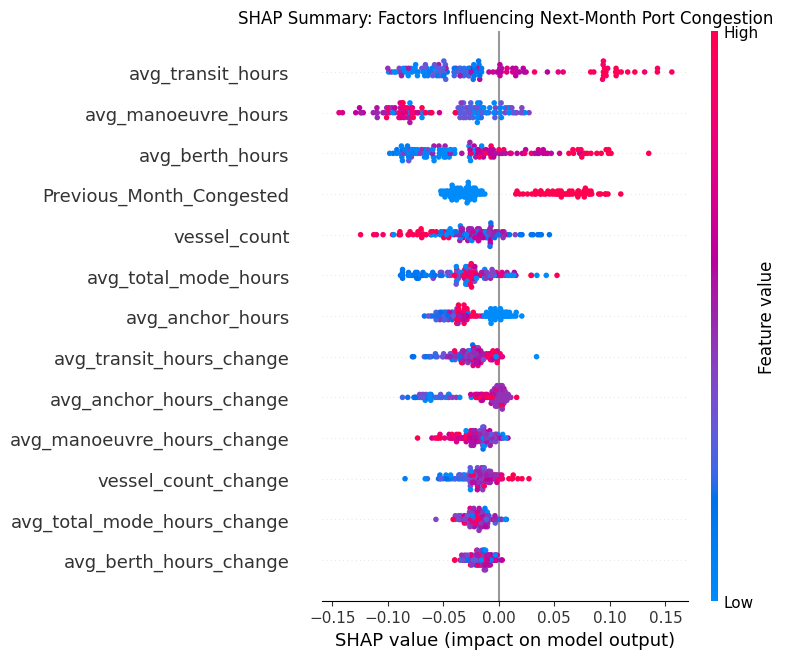

In [ ]:
import matplotlib.pyplot as plt

shap.summary_plot(
    shap_class1,
    X_final_test,
    feature_names=feature_cols,
    show=False
)

plt.title("SHAP Summary: Factors Influencing Next-Month Port Congestion")
plt.tight_layout()
plt.show()


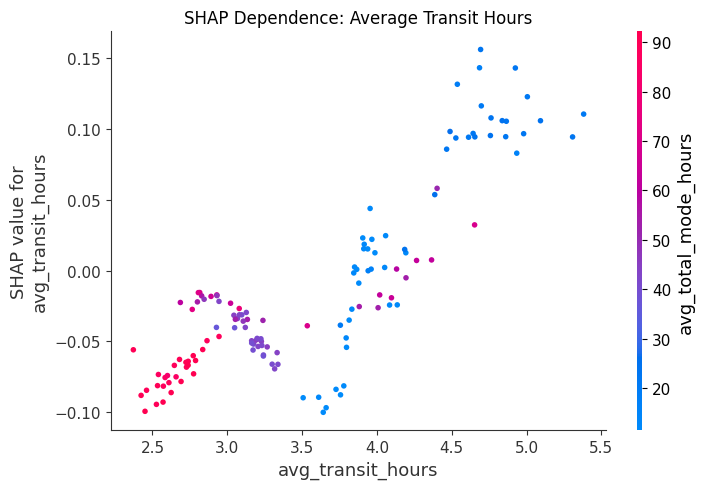

In [ ]:
shap.dependence_plot(
    "avg_transit_hours",
    shap_class1,
    X_final_test,
    feature_names=feature_cols,
    show=False
)

plt.title("SHAP Dependence: Average Transit Hours")
plt.tight_layout()
plt.show()

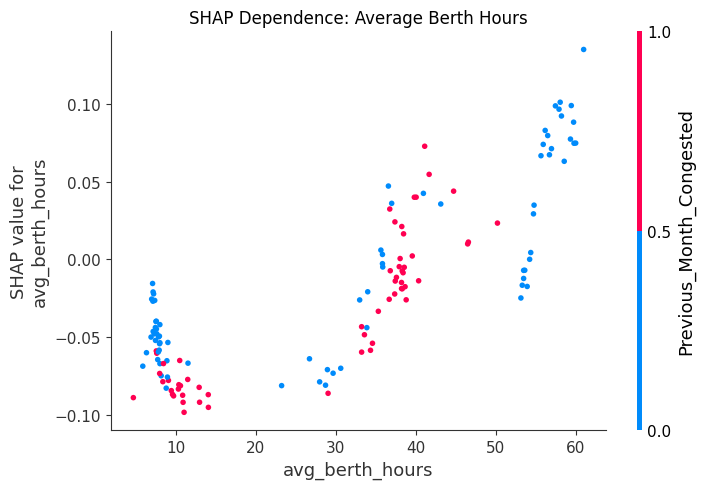

In [ ]:
shap.dependence_plot(
    "avg_berth_hours",
    shap_class1,
    X_final_test,
    feature_names=feature_cols,
    show=False
)

plt.title("SHAP Dependence: Average Berth Hours")
plt.tight_layout()
plt.show()

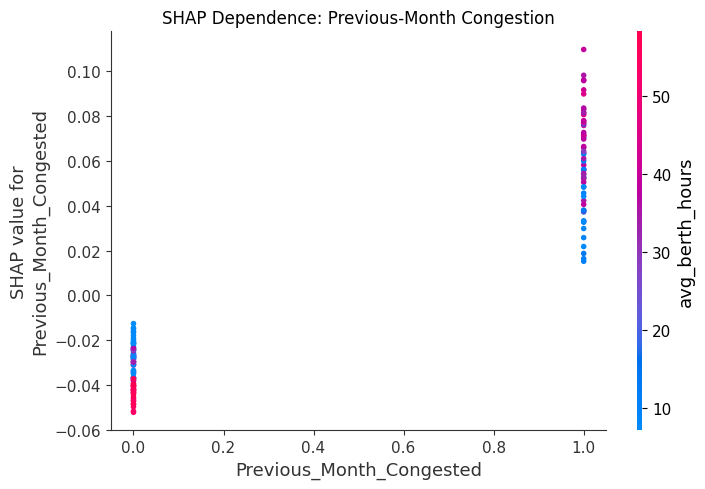

In [ ]:
shap.dependence_plot(
    "Previous_Month_Congested",
    shap_class1,
    X_final_test,
    feature_names=feature_cols,
    show=False
)

plt.title("SHAP Dependence: Previous-Month Congestion")
plt.tight_layout()
plt.show()

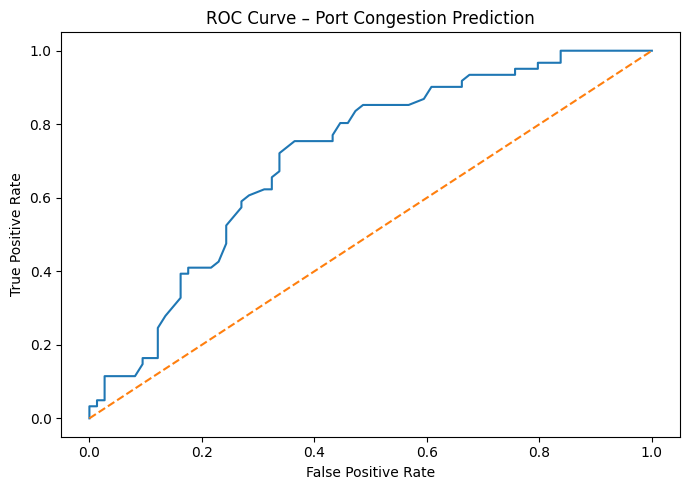

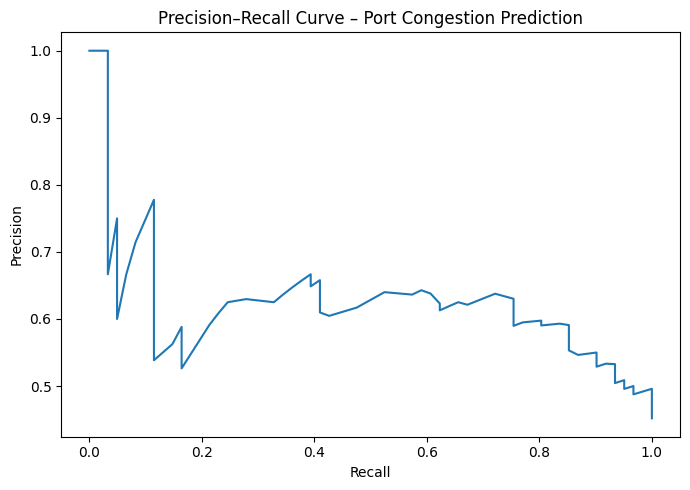

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve

# ROC curve
fpr, tpr, _ = roc_curve(y_final_test, final_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Port Congestion Prediction")
plt.tight_layout()
plt.show()

# Precision-Recall curve
precision, recall, _ = precision_recall_curve(
    y_final_test,
    final_prob
)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve – Port Congestion Prediction")
plt.tight_layout()
plt.show()

In [ ]:
print("Model data date range:")
print(model_data["YearMonth"].min(), "to", model_data["YearMonth"].max())

print("\nTarget missing values:")
print(model_data["Target_Next_Month"].isna().sum())

print("\nLast 10 rows:")
print(
    model_data[["Port", "YearMonth", "Target_Next_Month"]]
    .sort_values("YearMonth")
    .tail(10)
)

Model data date range:
2015-01-01 00:00:00 to 2025-12-01 00:00:00

Target missing values:
0

Last 10 rows:
              Port  YearMonth  Target_Next_Month
648       Savannah 2025-11-01                  0
647          NY_NJ 2025-11-01                  0
649        Seattle 2025-11-01                  1
645        Houston 2025-11-01                  0
646  LA_Long_Beach 2025-11-01                  0
652          NY_NJ 2025-12-01                  1
653       Savannah 2025-12-01                  1
650        Houston 2025-12-01                  0
651  LA_Long_Beach 2025-12-01                  0
654        Seattle 2025-12-01                  1


In [ ]:
print("December 2025 target values:")
print(
    model_data.loc[
        model_data["YearMonth"] == "2025-12-01",
        ["Port", "YearMonth", "Target_Next_Month"]
    ]
)

print("\nNovember 2025 target values:")
print(
    model_data.loc[
        model_data["YearMonth"] == "2025-11-01",
        ["Port", "YearMonth", "Target_Next_Month"]
    ]
)


December 2025 target values:
              Port  YearMonth  Target_Next_Month
650        Houston 2025-12-01                  0
651  LA_Long_Beach 2025-12-01                  0
652          NY_NJ 2025-12-01                  1
653       Savannah 2025-12-01                  1
654        Seattle 2025-12-01                  1

November 2025 target values:
              Port  YearMonth  Target_Next_Month
645        Houston 2025-11-01                  0
646  LA_Long_Beach 2025-11-01                  0
647          NY_NJ 2025-11-01                  0
648       Savannah 2025-11-01                  0
649        Seattle 2025-11-01                  1


In [ ]:
model_data = model_data[
    model_data["YearMonth"] < "2025-12-01"
].copy()

model_data = model_data.reset_index(drop=True)

print("Corrected date range:")
print(model_data["YearMonth"].min(), "to", model_data["YearMonth"].max())

print("\nShape:")
print(model_data.shape)

print("\nTarget missing values:")
print(model_data["Target_Next_Month"].isna().sum())

Corrected date range:
2015-01-01 00:00:00 to 2025-11-01 00:00:00

Shape:
(650, 16)

Target missing values:
0


In [ ]:

# Chronological split point: first 20% of months reserved for testing
unique_months = sorted(model_data["YearMonth"].unique())
test_start_month = unique_months[int(len(unique_months) * 0.8)]

print("Test period starts:", test_start_month)

# Calculate congestion thresholds using TRAINING PERIOD ONLY
training_dwell = dwell[
    dwell["YearMonth"] < test_start_month
].copy()

port_thresholds = (
    training_dwell.groupby("Port")["MeanDwellDays"]
    .quantile(0.75)
)

print("\nTraining-period congestion thresholds:")
print(port_thresholds)

# Apply those fixed thresholds to the complete dwell dataset
dwell["Congested"] = (
    dwell["MeanDwellDays"]
    > dwell["Port"].map(port_thresholds)
).astype(int)

# Predict NEXT month's congestion
dwell["Target_Next_Month"] = (
    dwell.groupby("Port")["Congested"].shift(-1)
)

# Remove December 2025 because January 2026 is unavailable
dwell = dwell[dwell["YearMonth"] < "2025-12-01"].copy()

# Remove any remaining missing targets
dwell = dwell.dropna(subset=["Target_Next_Month"])
dwell["Target_Next_Month"] = dwell["Target_Next_Month"].astype(int)

print("\nTarget date range:")
print(dwell["YearMonth"].min(), "to", dwell["YearMonth"].max())

print("\nTarget distribution:")
print(dwell["Target_Next_Month"].value_counts())

print("\nDwell shape:")
print(dwell.shape)

Test period starts: 2023-10-01 00:00:00

Training-period congestion thresholds:
Port
Houston          4.770854
LA_Long_Beach    5.690606
NY_NJ            3.569230
Savannah         2.213859
Seattle          4.904131
Name: MeanDwellDays, dtype: float64

Target date range:
2015-01-01 00:00:00 to 2025-11-01 00:00:00

Target distribution:
Target_Next_Month
0    451
1    194
Name: count, dtype: int64

Dwell shape:
(645, 16)


In [ ]:

# Reload the original dwell dataset
dwell = pd.read_csv("/content/monthly_dwell_2015_2025.csv")

dwell["YearMonth"] = pd.to_datetime(dwell["YearMonth"])

# Use training period only to determine congestion thresholds
training_dwell = dwell[
    dwell["YearMonth"] < test_start_month
].copy()

port_thresholds = (
    training_dwell.groupby("Port")["MeanDwellDays"]
    .quantile(0.75)
)

# Define congestion using fixed training-period thresholds
dwell["Congested"] = (
    dwell["MeanDwellDays"]
    > dwell["Port"].map(port_thresholds)
).astype(int)

# Predict next month's congestion
dwell["Target_Next_Month"] = (
    dwell.groupby("Port")["Congested"].shift(-1)
)

# Remove December 2025 because there is no January 2026
dwell = dwell[dwell["YearMonth"] < "2025-12-01"].copy()

# Remove rows without a valid next-month target
dwell = dwell.dropna(subset=["Target_Next_Month"])
dwell["Target_Next_Month"] = dwell["Target_Next_Month"].astype(int)

print("Dwell shape:", dwell.shape)
print("Date range:", dwell["YearMonth"].min(), "to", dwell["YearMonth"].max())
print("\nTarget distribution:")
print(dwell["Target_Next_Month"].value_counts())

Dwell shape: (650, 15)
Date range: 2015-01-01 00:00:00 to 2025-11-01 00:00:00

Target distribution:
Target_Next_Month
0    456
1    194
Name: count, dtype: int64


In [ ]:

# Rebuild model dataset using the corrected target
model_data = pd.merge(
    monthly_features,
    dwell[["Port", "YearMonth", "Target_Next_Month"]],
    on=["Port", "YearMonth"],
    how="inner"
)

# Sort chronologically
model_data = (
    model_data
    .sort_values(["YearMonth", "Port"])
    .reset_index(drop=True)
)

print("Model data shape:", model_data.shape)
print("Date range:", model_data["YearMonth"].min(), "to", model_data["YearMonth"].max())

print("\nTarget distribution:")
print(model_data["Target_Next_Month"].value_counts())

print("\nMissing values:")
print(model_data.isna().sum().sum())

Model data shape: (650, 9)
Date range: 2015-01-01 00:00:00 to 2025-11-01 00:00:00

Target distribution:
Target_Next_Month
0    456
1    194
Name: count, dtype: int64

Missing values:
0


In [ ]:

# Previous month's congestion state
model_data["Previous_Month_Congested"] = (
    model_data.groupby("Port")["Target_Next_Month"].shift(1)
)

# For the first month of each port, no previous month exists
model_data["Previous_Month_Congested"] = (
    model_data["Previous_Month_Congested"].fillna(0)
)

# Vessel behavior features
feature_cols = [
    "avg_anchor_hours",
    "avg_berth_hours",
    "avg_manoeuvre_hours",
    "avg_transit_hours",
    "avg_total_mode_hours",
    "vessel_count"
]

# Month-to-month changes
for col in feature_cols:
    model_data[f"{col}_change"] = (
        model_data.groupby("Port")[col].diff()
    )

change_cols = [
    col for col in model_data.columns
    if col.endswith("_change")
]

model_data[change_cols] = (
    model_data[change_cols].fillna(0)
)

# Final feature list
feature_cols = feature_cols + [
    "Previous_Month_Congested"
] + change_cols

print("Number of features:", len(feature_cols))
print("\nFeatures:")
print(feature_cols)

print("\nMissing values in features:")
print(model_data[feature_cols].isna().sum().sum())

Number of features: 13

Features:
['avg_anchor_hours', 'avg_berth_hours', 'avg_manoeuvre_hours', 'avg_transit_hours', 'avg_total_mode_hours', 'vessel_count', 'Previous_Month_Congested', 'avg_anchor_hours_change', 'avg_berth_hours_change', 'avg_manoeuvre_hours_change', 'avg_transit_hours_change', 'avg_total_mode_hours_change', 'vessel_count_change']

Missing values in features:
0


In [ ]:

# Get unique months in chronological order
unique_months = sorted(model_data["YearMonth"].unique())

# 80% of months for development, final 20% for testing
test_start_month = unique_months[int(len(unique_months) * 0.8)]

# Final train/test split
train_data = model_data[
    model_data["YearMonth"] < test_start_month
].copy()

test_data = model_data[
    model_data["YearMonth"] >= test_start_month
].copy()

# Validation split inside the training period
train_months = sorted(train_data["YearMonth"].unique())

validation_start_month = train_months[int(len(train_months) * 0.8)]

train_model_data = train_data[
    train_data["YearMonth"] < validation_start_month
].copy()

validation_data = train_data[
    train_data["YearMonth"] >= validation_start_month
].copy()

print("FINAL TRAINING PERIOD:")
print(train_data["YearMonth"].min(), "to", train_data["YearMonth"].max())
print("Rows:", len(train_data))

print("\nFINAL TEST PERIOD:")
print(test_data["YearMonth"].min(), "to", test_data["YearMonth"].max())
print("Rows:", len(test_data))

print("\nMODEL TRAINING PERIOD:")
print(train_model_data["YearMonth"].min(), "to", train_model_data["YearMonth"].max())
print("Rows:", len(train_model_data))

print("\nVALIDATION PERIOD:")
print(validation_data["YearMonth"].min(), "to", validation_data["YearMonth"].max())
print("Rows:", len(validation_data))

FINAL TRAINING PERIOD:
2015-01-01 00:00:00 to 2023-09-01 00:00:00
Rows: 520

FINAL TEST PERIOD:
2023-10-01 00:00:00 to 2025-11-01 00:00:00
Rows: 130

MODEL TRAINING PERIOD:
2015-01-01 00:00:00 to 2021-11-01 00:00:00
Rows: 415

VALIDATION PERIOD:
2021-12-01 00:00:00 to 2023-09-01 00:00:00
Rows: 105


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

X_train_model = train_model_data[feature_cols]
y_train_model = train_model_data["Target_Next_Month"]

X_val = validation_data[feature_cols]
y_val = validation_data["Target_Next_Month"]

validation_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

validation_model.fit(X_train_model, y_train_model)

val_prob = validation_model.predict_proba(X_val)[:, 1]

print("Validation model trained.")
print("Validation predictions:", len(val_prob))

Validation model trained.
Validation predictions: 105


In [ ]:

from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [i / 100 for i in range(10, 51)]:
    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

threshold_results = pd.DataFrame(threshold_results)

best_threshold = threshold_results.loc[
    threshold_results["F1"].idxmax(),
    "Threshold"
]

print("Best threshold:", best_threshold)

print("\nTop 10 thresholds by F1:")
print(
    threshold_results
    .sort_values("F1", ascending=False)
    .head(10)
    .to_string(index=False)
)

Best threshold: 0.15

Top 10 thresholds by F1:
 Threshold  Precision   Recall       F1
      0.15   0.445783 0.948718 0.606557
      0.19   0.470588 0.820513 0.598131
      0.16   0.439024 0.923077 0.595041
      0.14   0.420455 0.948718 0.582677
      0.24   0.531915 0.641026 0.581395
      0.17   0.435897 0.871795 0.581197
      0.18   0.440000 0.846154 0.578947
      0.23   0.509804 0.666667 0.577778
      0.20   0.460317 0.743590 0.568627
      0.22   0.482143 0.692308 0.568421


In [ ]:

from sklearn.ensemble import RandomForestClassifier

X_final_train = train_data[feature_cols]
y_final_train = train_data["Target_Next_Month"]

X_final_test = test_data[feature_cols]
y_final_test = test_data["Target_Next_Month"]

final_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

final_model.fit(X_final_train, y_final_train)

final_prob = final_model.predict_proba(X_final_test)[:, 1]

# Use threshold selected ONLY from validation data
final_pred = (final_prob >= best_threshold).astype(int)

print("Final model trained.")
print("Test predictions:", len(final_pred))
print("Threshold used:", best_threshold)

Final model trained.
Test predictions: 130
Threshold used: 0.15


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_final_test, final_pred)
precision = precision_score(y_final_test, final_pred, zero_division=0)
recall = recall_score(y_final_test, final_pred, zero_division=0)
f1 = f1_score(y_final_test, final_pred, zero_division=0)

roc_auc = roc_auc_score(y_final_test, final_prob)
pr_auc = average_precision_score(y_final_test, final_prob)

cm = confusion_matrix(y_final_test, final_pred)

print("CORRECTED FINAL TEST RESULTS")
print("=" * 35)
print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")
print(f"ROC-AUC:   {roc_auc:.3f}")
print(f"PR-AUC:    {pr_auc:.3f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_final_test,
        final_pred,
        target_names=["Non-Congested", "Congested"],
        zero_division=0
    )
)

CORRECTED FINAL TEST RESULTS
Accuracy:  0.815
Precision: 0.750
Recall:    0.986
F1-score:  0.852
ROC-AUC:   0.924
PR-AUC:    0.899

Confusion Matrix:
[[37 23]
 [ 1 69]]

Classification Report:
               precision    recall  f1-score   support

Non-Congested       0.97      0.62      0.76        60
    Congested       0.75      0.99      0.85        70

     accuracy                           0.82       130
    macro avg       0.86      0.80      0.80       130
 weighted avg       0.85      0.82      0.81       130



In [ ]:

import shap
import matplotlib.pyplot as plt

# Explain the corrected final model
explainer = shap.TreeExplainer(final_model)

shap_values = explainer.shap_values(X_final_test)

print("SHAP output shape:", shap_values.shape)

# Binary Random Forest: take class 1 = Congested
shap_class1 = shap_values[:, :, 1]

print("Class-1 SHAP shape:", shap_class1.shape)

SHAP output shape: (130, 13, 2)
Class-1 SHAP shape: (130, 13)


In [ ]:

import pandas as pd

shap_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Mean_Absolute_SHAP": abs(shap_class1).mean(axis=0)
})

shap_importance = (
    shap_importance
    .sort_values("Mean_Absolute_SHAP", ascending=False)
    .reset_index(drop=True)
)

print("CORRECTED SHAP FEATURE IMPORTANCE")
print("=" * 40)
print(shap_importance.to_string(index=False))

CORRECTED SHAP FEATURE IMPORTANCE
                    Feature  Mean_Absolute_SHAP
   Previous_Month_Congested            0.090968
        avg_manoeuvre_hours            0.054734
          avg_transit_hours            0.044113
               vessel_count            0.040327
            avg_berth_hours            0.032068
       avg_total_mode_hours            0.029305
   avg_transit_hours_change            0.024846
        vessel_count_change            0.023707
           avg_anchor_hours            0.019427
 avg_manoeuvre_hours_change            0.018177
     avg_berth_hours_change            0.017721
avg_total_mode_hours_change            0.014714
    avg_anchor_hours_change            0.014420


In [ ]:

# Remove previous-month congestion to test
# whether vessel behavior alone provides predictive information

feature_cols_behavior = [
    col for col in feature_cols
    if col != "Previous_Month_Congested"
]

X_train_behavior = train_data[feature_cols_behavior]
y_train_behavior = train_data["Target_Next_Month"]

X_test_behavior = test_data[feature_cols_behavior]
y_test_behavior = test_data["Target_Next_Month"]

behavior_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

behavior_model.fit(X_train_behavior, y_train_behavior)

behavior_prob = behavior_model.predict_proba(
    X_test_behavior
)[:, 1]

# Use the same threshold selected from the validation process
behavior_pred = (
    behavior_prob >= best_threshold
).astype(int)

print("Behavior-only model trained.")
print("Number of features:", len(feature_cols_behavior))
print("Test predictions:", len(behavior_pred))

Behavior-only model trained.
Number of features: 12
Test predictions: 130


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

behavior_accuracy = accuracy_score(y_test_behavior, behavior_pred)
behavior_precision = precision_score(
    y_test_behavior, behavior_pred, zero_division=0
)
behavior_recall = recall_score(
    y_test_behavior, behavior_pred, zero_division=0
)
behavior_f1 = f1_score(
    y_test_behavior, behavior_pred, zero_division=0
)

behavior_roc_auc = roc_auc_score(
    y_test_behavior, behavior_prob
)
behavior_pr_auc = average_precision_score(
    y_test_behavior, behavior_prob
)

behavior_cm = confusion_matrix(
    y_test_behavior, behavior_pred
)

print("BEHAVIOR-ONLY MODEL RESULTS")
print("=" * 35)
print(f"Accuracy:  {behavior_accuracy:.3f}")
print(f"Precision: {behavior_precision:.3f}")
print(f"Recall:    {behavior_recall:.3f}")
print(f"F1-score:  {behavior_f1:.3f}")
print(f"ROC-AUC:   {behavior_roc_auc:.3f}")
print(f"PR-AUC:    {behavior_pr_auc:.3f}")

print("\nConfusion Matrix:")
print(behavior_cm)

BEHAVIOR-ONLY MODEL RESULTS
Accuracy:  0.808
Precision: 0.747
Recall:    0.971
F1-score:  0.845
ROC-AUC:   0.920
PR-AUC:    0.922

Confusion Matrix:
[[37 23]
 [ 2 68]]


In [ ]:

# SHAP explanation for the behavior-only model

behavior_explainer = shap.TreeExplainer(behavior_model)

behavior_shap_values = behavior_explainer.shap_values(
    X_test_behavior
)

print("SHAP output shape:", behavior_shap_values.shape)

# Binary classification: class 1 = Congested
behavior_shap_class1 = behavior_shap_values[:, :, 1]

print(
    "Class-1 SHAP shape:",
    behavior_shap_class1.shape
)

SHAP output shape: (130, 12, 2)
Class-1 SHAP shape: (130, 12)


In [ ]:

behavior_shap_importance = pd.DataFrame({
    "Feature": feature_cols_behavior,
    "Mean_Absolute_SHAP": abs(
        behavior_shap_class1
    ).mean(axis=0)
})

behavior_shap_importance = (
    behavior_shap_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

print("BEHAVIOR-ONLY SHAP FEATURE IMPORTANCE")
print("=" * 45)
print(
    behavior_shap_importance.to_string(index=False)
)

BEHAVIOR-ONLY SHAP FEATURE IMPORTANCE
                    Feature  Mean_Absolute_SHAP
        avg_manoeuvre_hours            0.070882
          avg_transit_hours            0.058733
               vessel_count            0.051861
            avg_berth_hours            0.040836
       avg_total_mode_hours            0.035903
   avg_transit_hours_change            0.026167
        vessel_count_change            0.020689
 avg_manoeuvre_hours_change            0.019428
           avg_anchor_hours            0.017815
     avg_berth_hours_change            0.016164
avg_total_mode_hours_change            0.015876
    avg_anchor_hours_change            0.014773


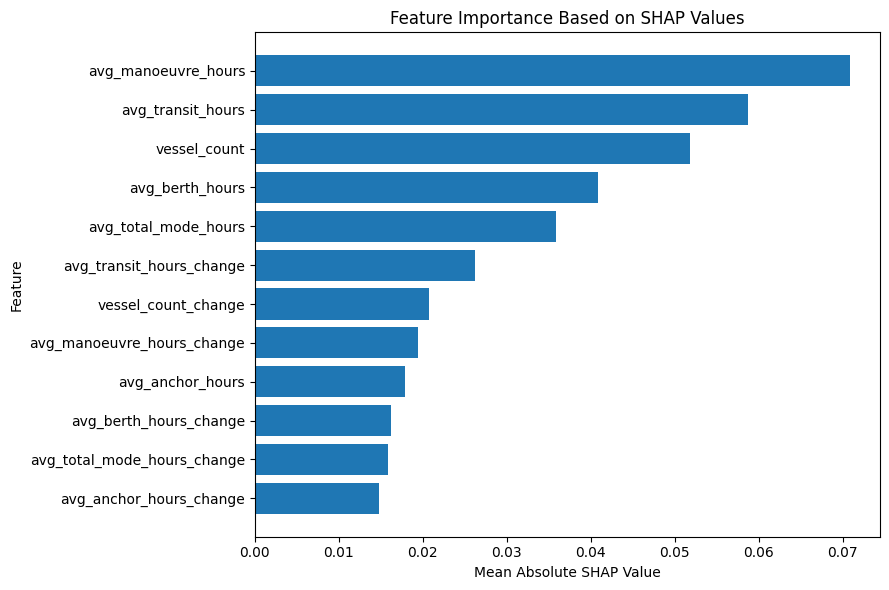

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.barh(
    behavior_shap_importance["Feature"],
    behavior_shap_importance["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Feature Importance Based on SHAP Values")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:

behavior_features = [
    "avg_manoeuvre_hours",
    "avg_transit_hours",
    "vessel_count",
    "avg_berth_hours",
    "avg_total_mode_hours",
    "avg_anchor_hours"
]

behavior_comparison = (
    model_data
    .groupby("Target_Next_Month")[behavior_features]
    .mean()
    .T
)

behavior_comparison.columns = [
    "Not Congested Next Month",
    "Congested Next Month"
]

print("AVERAGE VESSEL BEHAVIOR")
print("=" * 55)
print(behavior_comparison.round(3))

AVERAGE VESSEL BEHAVIOR
                      Not Congested Next Month  Congested Next Month
avg_manoeuvre_hours                      0.561                 0.637
avg_transit_hours                        3.303                 3.606
vessel_count                           262.770               232.557
avg_berth_hours                         24.724                29.513
avg_total_mode_hours                    40.287                46.544
avg_anchor_hours                        10.656                11.380


In [ ]:

port_behavior_comparison = (
    model_data
    .groupby(["Port", "Target_Next_Month"])[
        [
            "avg_manoeuvre_hours",
            "avg_transit_hours",
            "avg_berth_hours",
            "avg_total_mode_hours",
            "vessel_count"
        ]
    ]
    .mean()
    .round(3)
)

print("BEHAVIOR BY PORT AND NEXT-MONTH CONGESTION")
print("=" * 65)
print(port_behavior_comparison)

BEHAVIOR BY PORT AND NEXT-MONTH CONGESTION
                                 avg_manoeuvre_hours  avg_transit_hours  \
Port          Target_Next_Month                                           
Houston       0                                0.111              3.929   
              1                                0.120              4.233   
LA_Long_Beach 0                                1.182              2.874   
              1                                1.886              3.227   
NY_NJ         0                                0.392              3.820   
              1                                0.393              4.276   
Savannah      0                                0.646              3.192   
              1                                0.575              3.110   
Seattle       0                                0.419              2.641   
              1                                0.568              3.301   

                                 avg_berth_hours  avg_to

In [ ]:

# Calculate percentage change from non-congested to congested-next-month
port_pct_change = (
    port_behavior_comparison
    .unstack("Target_Next_Month")
)

percentage_change = (
    (port_pct_change.xs(1, level="Target_Next_Month", axis=1)
     - port_pct_change.xs(0, level="Target_Next_Month", axis=1))
    / port_pct_change.xs(0, level="Target_Next_Month", axis=1)
) * 100

print("PERCENTAGE CHANGE BEFORE CONGESTION")
print("=" * 60)
print(percentage_change.round(1))

PERCENTAGE CHANGE BEFORE CONGESTION
               avg_manoeuvre_hours  avg_transit_hours  avg_berth_hours  \
Port                                                                     
Houston                        8.1                7.7             -5.0   
LA_Long_Beach                 59.6               12.3             29.9   
NY_NJ                          0.3               11.9             16.1   
Savannah                     -11.0               -2.6             31.9   
Seattle                       35.6               25.0             42.8   

               avg_total_mode_hours  vessel_count  
Port                                               
Houston                        -1.5         -16.4  
LA_Long_Beach                  34.7           8.0  
NY_NJ                          13.1           3.6  
Savannah                       28.8          12.6  
Seattle                        33.0          16.0  


In [ ]:

from scipy.stats import mannwhitneyu

test_features = [
    "avg_manoeuvre_hours",
    "avg_transit_hours",
    "avg_berth_hours",
    "avg_total_mode_hours",
    "vessel_count"
]

results = []

for port in model_data["Port"].unique():

    port_data = model_data[model_data["Port"] == port]

    for feature in test_features:

        not_congested = port_data[
            port_data["Target_Next_Month"] == 0
        ][feature]

        congested = port_data[
            port_data["Target_Next_Month"] == 1
        ][feature]

        statistic, p_value = mannwhitneyu(
            not_congested,
            congested,
            alternative="two-sided"
        )

        results.append({
            "Port": port,
            "Feature": feature,
            "p_value": p_value
        })

significance_results = pd.DataFrame(results)

significance_results["Significant_0.05"] = (
    significance_results["p_value"] < 0.05
)

print("MANN-WHITNEY U TEST RESULTS")
print("=" * 60)
print(significance_results.to_string(index=False))

MANN-WHITNEY U TEST RESULTS
         Port              Feature      p_value  Significant_0.05
      Houston  avg_manoeuvre_hours 3.436952e-02              True
      Houston    avg_transit_hours 3.920743e-05              True
      Houston      avg_berth_hours 2.374569e-02              True
      Houston avg_total_mode_hours 2.097356e-01             False
      Houston         vessel_count 2.907815e-04              True
LA_Long_Beach  avg_manoeuvre_hours 2.671311e-07              True
LA_Long_Beach    avg_transit_hours 2.932559e-04              True
LA_Long_Beach      avg_berth_hours 6.914413e-08              True
LA_Long_Beach avg_total_mode_hours 7.213545e-10              True
LA_Long_Beach         vessel_count 1.486131e-01             False
        NY_NJ  avg_manoeuvre_hours 9.074151e-01             False
        NY_NJ    avg_transit_hours 6.438428e-06              True
        NY_NJ      avg_berth_hours 3.753575e-04              True
        NY_NJ avg_total_mode_hours 4.139344e-05 

In [ ]:

from statsmodels.stats.multitest import multipletests

# Benjamini-Hochberg correction for all 25 tests
reject, corrected_p, _, _ = multipletests(
    significance_results["p_value"],
    alpha=0.05,
    method="fdr_bh"
)

significance_results["Adjusted_p_value"] = corrected_p
significance_results["Significant_after_BH"] = reject

print("MULTIPLE-TEST CORRECTED RESULTS")
print("=" * 70)
print(
    significance_results[
        [
            "Port",
            "Feature",
            "p_value",
            "Adjusted_p_value",
            "Significant_after_BH"
        ]
    ].to_string(index=False)
)

MULTIPLE-TEST CORRECTED RESULTS
         Port              Feature      p_value  Adjusted_p_value  Significant_after_BH
      Houston  avg_manoeuvre_hours 3.436952e-02      4.091609e-02                  True
      Houston    avg_transit_hours 3.920743e-05      7.960277e-05                  True
      Houston      avg_berth_hours 2.374569e-02      2.968211e-02                  True
      Houston avg_total_mode_hours 2.097356e-01      2.279735e-01                 False
      Houston         vessel_count 2.907815e-04      4.582124e-04                  True
LA_Long_Beach  avg_manoeuvre_hours 2.671311e-07      8.347848e-07                  True
LA_Long_Beach    avg_transit_hours 2.932559e-04      4.582124e-04                  True
LA_Long_Beach      avg_berth_hours 6.914413e-08      2.469433e-07                  True
LA_Long_Beach avg_total_mode_hours 7.213545e-10      3.005644e-09                  True
LA_Long_Beach         vessel_count 1.486131e-01      1.688785e-01                 False


In [ ]:

model_comparison = pd.DataFrame({
    "Model": [
        "Behavior-only",
        "Behavior + Previous Congestion"
    ],
    "Accuracy": [
        0.808,
        0.815
    ],
    "Precision": [
        0.747,
        0.750
    ],
    "Recall": [
        0.971,
        0.986
    ],
    "F1": [
        0.845,
        0.852
    ],
    "ROC_AUC": [
        0.920,
        0.924
    ],
    "PR_AUC": [
        0.922,
        0.899
    ]
})

print(model_comparison.round(3))

                            Model  Accuracy  Precision  Recall     F1  \
0                   Behavior-only     0.808      0.747   0.971  0.845   
1  Behavior + Previous Congestion     0.815      0.750   0.986  0.852   

   ROC_AUC  PR_AUC  
0    0.920   0.922  
1    0.924   0.899  


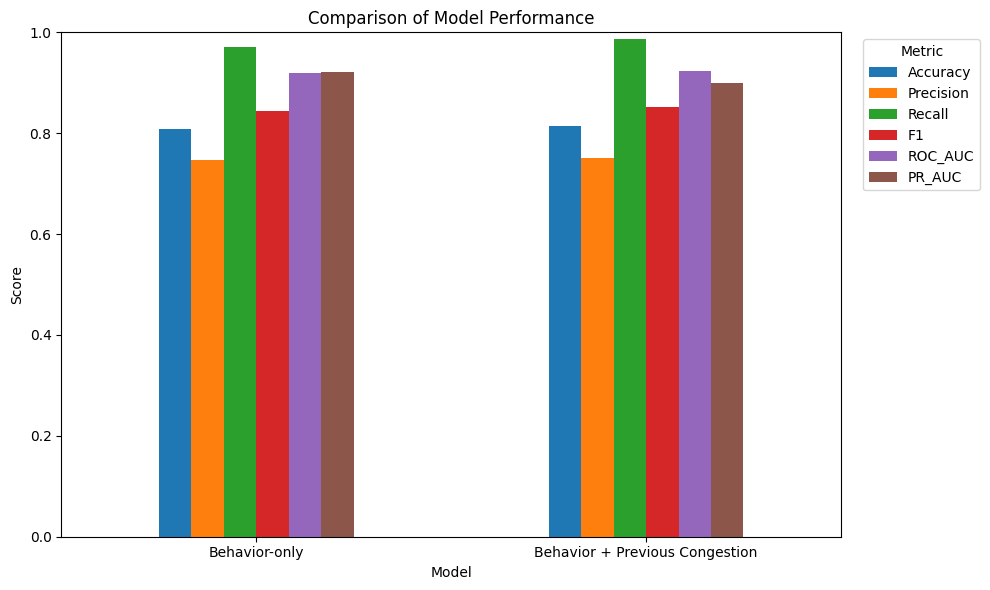

In [ ]:

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

plot_data = model_comparison.set_index("Model")[metrics_to_plot]

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_title("Comparison of Model Performance")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# ROC curves
fpr_behavior, tpr_behavior, _ = roc_curve(
    y_test_behavior,
    behavior_prob
)

fpr_full, tpr_full, _ = roc_curve(
    y_test,
    final_prob
)

roc_auc_behavior = auc(fpr_behavior, tpr_behavior)
roc_auc_full = auc(fpr_full, tpr_full)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_behavior,
    tpr_behavior,
    label=f"Behavior-only (AUC = {roc_auc_behavior:.3f})"
)

plt.plot(
    fpr_full,
    tpr_full,
    label=f"Behavior + Previous Congestion (AUC = {roc_auc_full:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Congestion Prediction")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

ValueError: Found input variables with inconsistent numbers of samples: [131, 130]

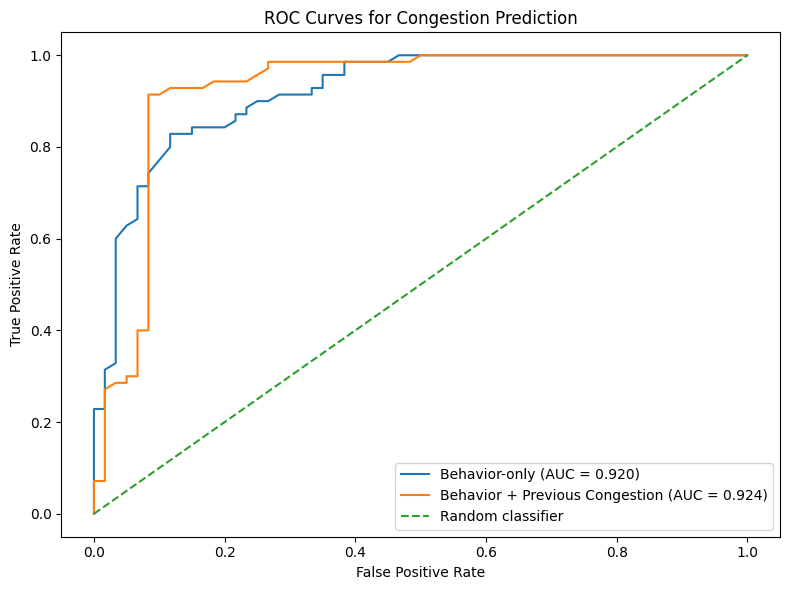

In [ ]:

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Recreate the correct target for the final 130-row test set
y_test_final = test_data["Target_Next_Month"]

# ROC curves
fpr_behavior, tpr_behavior, _ = roc_curve(
    y_test_behavior,
    behavior_prob
)

fpr_full, tpr_full, _ = roc_curve(
    y_test_final,
    final_prob
)

roc_auc_behavior = auc(fpr_behavior, tpr_behavior)
roc_auc_full = auc(fpr_full, tpr_full)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_behavior,
    tpr_behavior,
    label=f"Behavior-only (AUC = {roc_auc_behavior:.3f})"
)

plt.plot(
    fpr_full,
    tpr_full,
    label=f"Behavior + Previous Congestion (AUC = {roc_auc_full:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Congestion Prediction")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

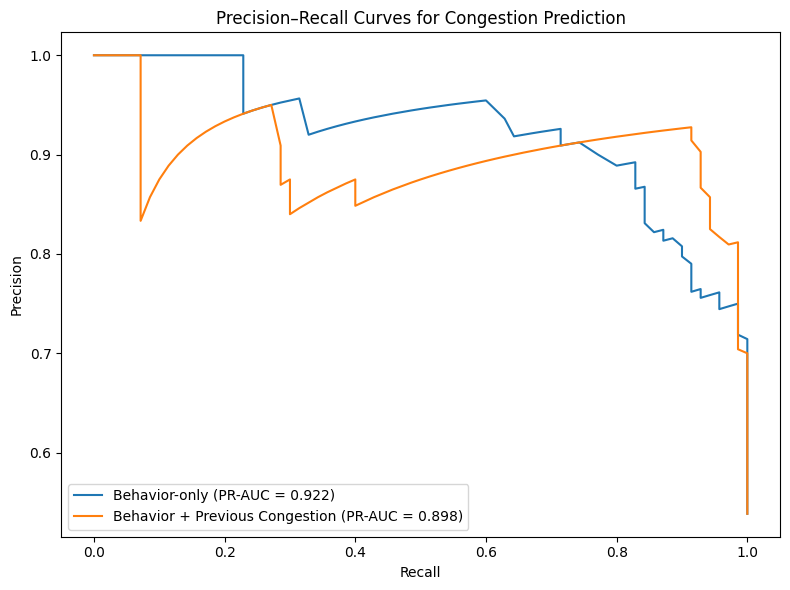

In [ ]:

from sklearn.metrics import precision_recall_curve, auc
import matplotlib.pyplot as plt

# Precision-Recall curves
precision_behavior, recall_behavior, _ = precision_recall_curve(
    y_test_behavior,
    behavior_prob
)

precision_full, recall_full, _ = precision_recall_curve(
    y_test_final,
    final_prob
)

pr_auc_behavior = auc(
    recall_behavior,
    precision_behavior
)

pr_auc_full = auc(
    recall_full,
    precision_full
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_behavior,
    precision_behavior,
    label=f"Behavior-only (PR-AUC = {pr_auc_behavior:.3f})"
)

plt.plot(
    recall_full,
    precision_full,
    label=f"Behavior + Previous Congestion (PR-AUC = {pr_auc_full:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves for Congestion Prediction")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

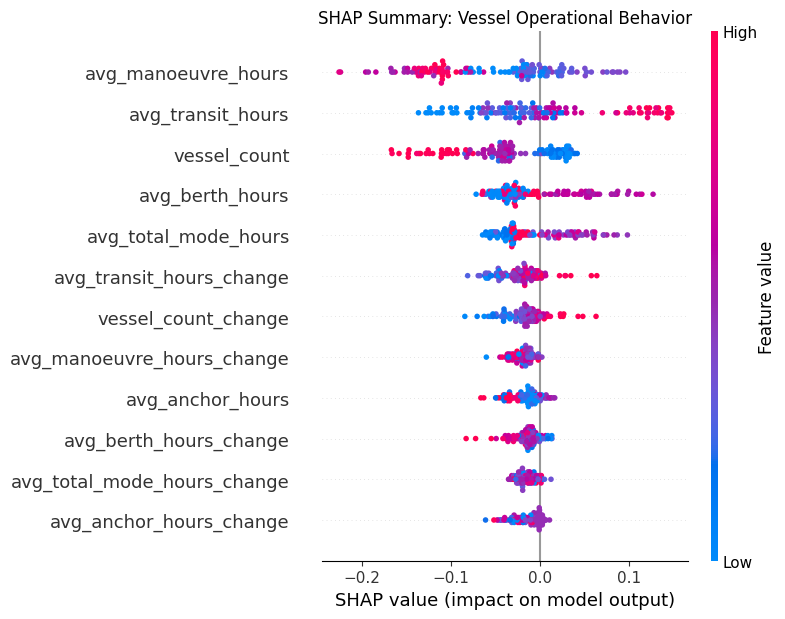

In [ ]:

import shap
import matplotlib.pyplot as plt

shap.summary_plot(
    behavior_shap_class1,
    X_test_behavior,
    feature_names=feature_cols_behavior,
    show=False
)

plt.title("SHAP Summary: Vessel Operational Behavior")
plt.tight_layout()
plt.show()

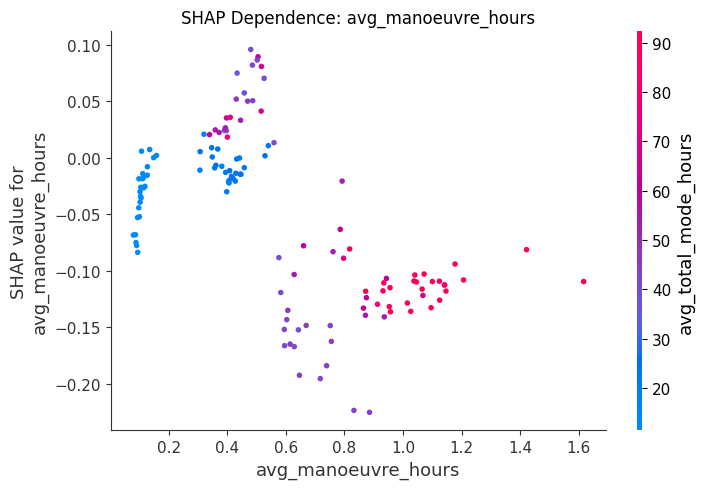

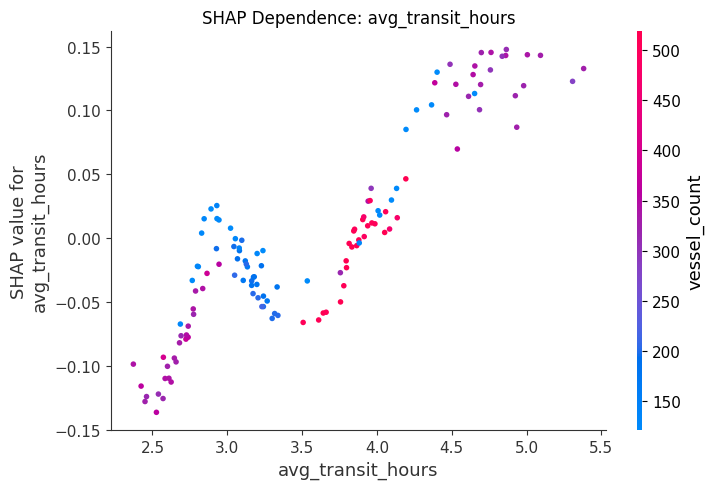

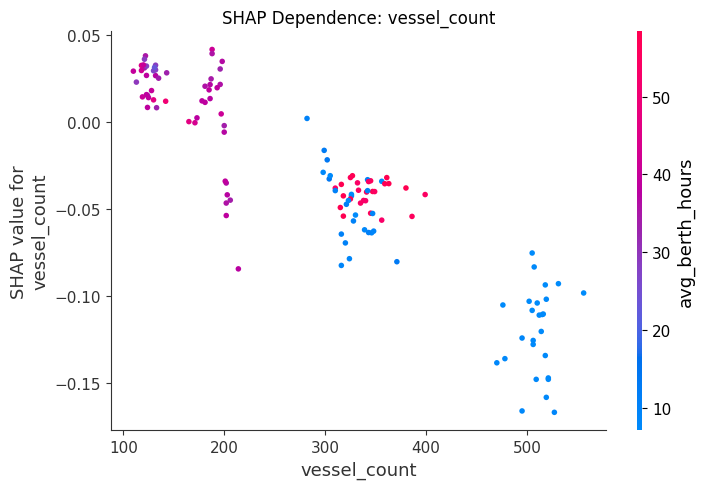

In [ ]:

top_features = [
    "avg_manoeuvre_hours",
    "avg_transit_hours",
    "vessel_count"
]

for feature in top_features:
    shap.dependence_plot(
        feature,
        behavior_shap_class1,
        X_test_behavior,
        show=False
    )

    plt.title(f"SHAP Dependence: {feature}")
    plt.tight_layout()
    plt.show()

In [ ]:

# Analyze how vessel count affects the SHAP value

vessel_shap_data = pd.DataFrame({
    "vessel_count": X_test_behavior["vessel_count"].values,
    "SHAP_value": behavior_shap_class1[
        :, feature_cols_behavior.index("vessel_count")
    ]
})

# Create vessel-count groups
vessel_shap_data["Vessel_Group"] = pd.qcut(
    vessel_shap_data["vessel_count"],
    q=4,
    duplicates="drop"
)

summary = (
    vessel_shap_data
    .groupby("Vessel_Group", observed=True)
    .agg(
        Average_Vessel_Count=("vessel_count", "mean"),
        Average_SHAP=("SHAP_value", "mean")
    )
    .reset_index()
)

print("VESSEL COUNT SHAP ANALYSIS")
print("=" * 55)
print(summary.round(4).to_string(index=False))

VESSEL COUNT SHAP ANALYSIS
     Vessel_Group  Average_Vessel_Count  Average_SHAP
(109.999, 185.25]              136.5455        0.0212
  (185.25, 318.0]              244.0606       -0.0190
  (318.0, 358.25]              336.8387       -0.0470
  (358.25, 556.0]              480.9091       -0.1045


In [ ]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Test predictions from the behavior-only model
test_results = test_data[["Port", "Target_Next_Month"]].copy()

test_results["Predicted"] = behavior_pred
test_results["Probability"] = behavior_prob

port_results = []

for port in test_results["Port"].unique():

    port_data = test_results[
        test_results["Port"] == port
    ]

    y_true_port = port_data["Target_Next_Month"]
    y_pred_port = port_data["Predicted"]
    y_prob_port = port_data["Probability"]

    port_results.append({
        "Port": port,
        "Samples": len(port_data),
        "Accuracy": accuracy_score(
            y_true_port,
            y_pred_port
        ),
        "Precision": precision_score(
            y_true_port,
            y_pred_port,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true_port,
            y_pred_port,
            zero_division=0
        ),
        "F1": f1_score(
            y_true_port,
            y_pred_port,
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_true_port,
            y_prob_port
        )
    })

port_performance = pd.DataFrame(port_results)

print("BEHAVIOR-ONLY MODEL: PERFORMANCE BY PORT")
print("=" * 70)
print(port_performance.round(3).to_string(index=False))

BEHAVIOR-ONLY MODEL: PERFORMANCE BY PORT
         Port  Samples  Accuracy  Precision  Recall    F1  ROC_AUC
      Houston       26     0.462      0.000   0.000 0.000    0.300
LA_Long_Beach       26     0.962      0.000   0.000 0.000      NaN
        NY_NJ       26     0.846      0.846   1.000 0.917    0.784
     Savannah       26     0.808      0.840   0.955 0.894    0.494
      Seattle       26     0.962      0.962   1.000 0.980    0.540


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


In [ ]:

port_class_distribution = (
    test_data
    .groupby(["Port", "Target_Next_Month"])
    .size()
    .unstack(fill_value=0)
)

port_class_distribution.columns = [
    "Not_Congested",
    "Congested"
]

print("TEST-SET CLASS DISTRIBUTION BY PORT")
print("=" * 55)
print(port_class_distribution)

TEST-SET CLASS DISTRIBUTION BY PORT
               Not_Congested  Congested
Port                                   
Houston                   25          1
LA_Long_Beach             26          0
NY_NJ                      4         22
Savannah                   4         22
Seattle                    1         25


In [ ]:

print("=" * 70)
print("FINAL STUDY RESULTS SUMMARY")
print("=" * 70)

print("\nDATASET")
print(f"Modeling observations: {len(model_data)}")
print(f"Ports: {model_data['Port'].nunique()}")
print(f"Time period: {model_data['YearMonth'].min().strftime('%Y-%m')} "
      f"to {model_data['YearMonth'].max().strftime('%Y-%m')}")

print("\nPRIMARY MODEL — BEHAVIOR ONLY")
print(f"Accuracy:  {accuracy_score(y_test_behavior, behavior_pred):.3f}")
print(f"Precision: {precision_score(y_test_behavior, behavior_pred):.3f}")
print(f"Recall:    {recall_score(y_test_behavior, behavior_pred):.3f}")
print(f"F1-score:  {f1_score(y_test_behavior, behavior_pred):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_behavior, behavior_prob):.3f}")
print(f"PR-AUC:    {pr_auc_behavior:.3f}")

print("\nPRIMARY SHAP FEATURES")
for _, row in behavior_shap_importance.head(5).iterrows():
    print(
        f"{row['Feature']}: "
        f"{row['Mean_Absolute_SHAP']:.4f}"
    )

print("\nTEST PERIOD")
print(f"Test observations: {len(test_data)}")
print(
    f"Congested: "
    f"{(test_data['Target_Next_Month'] == 1).sum()}"
)
print(
    f"Not congested: "
    f"{(test_data['Target_Next_Month'] == 0).sum()}"
)

FINAL STUDY RESULTS SUMMARY

DATASET
Modeling observations: 650
Ports: 5
Time period: 2015-01 to 2025-11

PRIMARY MODEL — BEHAVIOR ONLY
Accuracy:  0.808
Precision: 0.747
Recall:    0.971
F1-score:  0.845
ROC-AUC:   0.920
PR-AUC:    0.922

PRIMARY SHAP FEATURES
avg_manoeuvre_hours: 0.0709
avg_transit_hours: 0.0587
vessel_count: 0.0519
avg_berth_hours: 0.0408
avg_total_mode_hours: 0.0359

TEST PERIOD
Test observations: 130
Congested: 70
Not congested: 60
